# Example axisymmetric inductor with voltage excitation

This notebook is a voltage-excited copy of the current-driven inductor example.


In [ ]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / 'fem').is_dir():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from dataclasses import asdict

from model import (
    AirGapSpec, Constructor, CoreSpec, InsulationSpec, Material,
    MeshSettings, OutputSettings, RectangularConductor, RoundConductor,
    SolverSettings, WindingLayer, WindingSpec, load,
)
from fem import (
    COPPER_CONDUCTIVITY_AT_20C_S_PER_M,
    build_mesh,
    solve_voltage_excitation,
    integrated_current,
    copper_loss,
    inductance,
    magnetic_flux_density,
    FrequencyDomainResult,
    magnetic_field_intensity,
    winding_flux_linkage,
    winding_voltages,
    average_abs_current_density,
    compare_domainc_blocks,
    meeker_litz_properties,
    winding_copper_losses,
    core_losses,
    winding_litz_losses,
    PhysicalField,
    complex_relative_permeability,
    core_loss_density,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Define the model

All dimensions are in metres. The 14 conductor centres reproduce the supplied example geometry.

In [ ]:
FREQUENCY_HZ = 270_000.0
CURRENT_A = 4.5
CORE_RELATIVE_PERMEABILITY = 1500.0
CORE_LOSS_ANGLE_DEG = 5.0
CORE_CONDUCTIVITY = 0.6
CORE_RELATIVE_PERMITTIVITY = 100_000.0
CORE_PERMITTIVITY_LOSS_ANGLE_DEG = 25.0
CONDUCTOR_RADIUS_M = 0.0013
USE_LITZ = False
LITZ_NUMBER_STRANDS = 150
LITZ_STRAND_RADIUS_M = 100e-6
MESH_SIZE_M = 0.00025
SKIN_DEPTH_M = np.sqrt(
    2.0
    / (
        2.0
        * np.pi
        * FREQUENCY_HZ
        * 4e-7
        * np.pi
        * COPPER_CONDUCTIVITY_AT_20C_S_PER_M
    )
)
CONDUCTOR_MESH_SIZE_M = SKIN_DEPTH_M / 2.0

# Build the same 14-turn model through the reusable constructor module.
conductor = RoundConductor(
    "round_copper",
    radius=CONDUCTOR_RADIUS_M,
    material="copper",
    construction="litz" if USE_LITZ else "solid",
    strands=LITZ_NUMBER_STRANDS if USE_LITZ else None,
    strand_diameter=2.0 * LITZ_STRAND_RADIUS_M if USE_LITZ else None,
)
core = CoreSpec(
    name="core", material="core",
    outer_radius=0.019943733351606967,
    outer_half_height=0.018475,
    window_inner_radius=0.00745,
    window_outer_radius=0.0185,
    window_half_height=0.01475,
    core_type="Single",
)
insulation = InsulationSpec(
    c2w_left=0.003,
    c2w_right=0.00235,
    c2w_top=0.0073,
    c2w_bottom=0.001,
    w2w=0.0005,
)
inductor_winding = Constructor.place_winding(
    core=core,
    insulation=insulation,
    name="primary",
    conductor=conductor,
    circuit="primary",
    turns=14,
    radial_columns=2,
    current=CURRENT_A,
    traversal="inside2outside-bottom2top",
)
model = Constructor(
    core=core,
    windings=(inductor_winding,),
    air_gaps=(AirGapSpec(
        "center_gap", 0.003725, 0.0, 0.00745, 0.0005
    ),),
    insulation=insulation,
    metadata={"name": "example inductor"},
).build()
model.materials = [
    Material("core", relative_permeability=CORE_RELATIVE_PERMEABILITY, permeability_loss_angle_deg=CORE_LOSS_ANGLE_DEG, conductivity=CORE_CONDUCTIVITY, relative_permittivity=CORE_RELATIVE_PERMITTIVITY, permittivity_loss_angle_deg=CORE_PERMITTIVITY_LOSS_ANGLE_DEG),
    Material("air", relative_permeability=1.0),
    Material("copper", relative_permeability=1.0, conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M),
]
model.metadata.units = "m"
model.mesh = MeshSettings(max_size=MESH_SIZE_M, order=1)
model.solver = SolverSettings(type="axisymmetric_frequency_domain")
model.output = OutputSettings(fields=["A_phi", "B"])
model.excitation.frequency = FREQUENCY_HZ
model.excitation.circuits = {"primary": CURRENT_A}
model_data = asdict(model)
model_data.pop("_legacy", None)
assert len(model.windings[0].turns) == 14
model

FEMModel(schema='pyMagBEM', version=1, metadata=Metadata(name='example inductor', description='', author='', units='m', extra={'name': 'example inductor'}), geometry=Geometry(coordinate_system='axisymmetric_rz', core=Region(name='core', material='core', corners=[[0.0, -0.018475], [0.019943733351606967, -0.018475], [0.0, 0.018475], [0.019943733351606967, 0.018475]], center=None, size=None, extra={'core_type': 'Single', 'insulation_mm': {'c2w_left': 3.0, 'c2w_right': 2.35, 'c2w_top': 7.3, 'c2w_bottom': 1.0, 'w2w': 0.5}}), air_gaps=[Region(name='center_gap', material='air', corners=[], center=[0.003725, 0.0], size=[0.00745, 0.0005], extra={})], shunts=[], winding_window=Region(name='winding_window', material='air', corners=[[0.00745, -0.01475], [0.0185, -0.01475], [0.00745, 0.01475], [0.0185, 0.01475]], center=None, size=None, extra={}), extra={'name': 'example inductor'}), materials=[Material(name='core', relative_permeability=1500.0, permeability_loss_angle_deg=5.0, conductivity=0.6, re

In [8]:
# Save the model used by this notebook as a reusable JSON file.
MODEL_JSON = REPOSITORY_ROOT / 'notebooks' / 'example_inductor_generated.json'
MODEL_JSON.write_text(json.dumps(model_data, indent=2) + '\n', encoding='utf-8')
print(f'Saved model to {MODEL_JSON}')


Saved model to C:\Users\tpiepe\Repositories\pyMagBEM\notebooks\example_inductor_generated.json


In [ ]:
mesh = build_mesh(
    model,
    max_size=MESH_SIZE_M,
    conductor_size=CONDUCTOR_MESH_SIZE_M if not USE_LITZ else None,
)
litz_properties = (
    meeker_litz_properties(
        FREQUENCY_HZ,
        strand_diameter=2.0 * LITZ_STRAND_RADIUS_M,
        fill_factor=conductor.fill_factor,
    )
    if USE_LITZ else None
)
APPLIED_VOLTAGE_V = 700.0
solve_result = solve_voltage_excitation(
    mesh,
    frequency=FREQUENCY_HZ,
    voltage=APPLIED_VOLTAGE_V,
    winding="primary",
    turns=14,
    relative_permeability={"core": complex_relative_permeability(CORE_RELATIVE_PERMEABILITY, CORE_LOSS_ANGLE_DEG)},
    conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M,
    phasor_convention="cosine",
)
a_phi, solved_density, current_scale = solve_result
turn_voltages = {}
result = FrequencyDomainResult.from_solution(
    model, mesh, a_phi, solved_density,
    frequency_hz=FREQUENCY_HZ, turn_voltages=turn_voltages,
)
source_voltage = APPLIED_VOLTAGE_V
flux_density = magnetic_flux_density(mesh, a_phi)
field_intensity = magnetic_field_intensity(
    mesh, a_phi
)
current_density = solved_density
flux_density_magnitude = np.linalg.norm(flux_density, axis=1)
solid_losses = None
if not USE_LITZ:
    solid_losses = winding_copper_losses(
        mesh, solved_density, conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M
    )
core_mag_loss_w, core_el_loss_w, core_total_loss_w = core_losses(
    mesh, field_intensity, FREQUENCY_HZ, a_phi=a_phi,
    relative_permeability=CORE_RELATIVE_PERMEABILITY,
    loss_angle_deg=CORE_LOSS_ANGLE_DEG, conductivity=CORE_CONDUCTIVITY,
    relative_permittivity=CORE_RELATIVE_PERMITTIVITY,
    permittivity_loss_angle_deg=CORE_PERMITTIVITY_LOSS_ANGLE_DEG,
)
litz_losses = None
if litz_properties is not None:
    litz_losses = winding_litz_losses(
        mesh, solved_density, field_intensity, FREQUENCY_HZ,
        strand_diameter=2.0 * LITZ_STRAND_RADIUS_M,
        fill_factor=conductor.fill_factor,
    )
solved_current_a = integrated_current(mesh, solved_density['conductor_0'], 'conductor_0')
flux_linkage_wb = winding_flux_linkage(mesh, a_phi, CURRENT_A)
linkage_inductance_h = flux_linkage_wb / CURRENT_A

print(f'Frequency: {FREQUENCY_HZ:,.0f} Hz')
print(f'Applied voltage: {APPLIED_VOLTAGE_V:.3f} V')
print(f'Solved current: {solved_current_a:.6g} A')
print(f'Mesh: {len(mesh.points)} nodes, {len(mesh.triangles)} triangles')
mean_j = average_abs_current_density(mesh, solved_density['conductor_0'], 'conductor_0')
print(f'Average |J| conductor 0: {mean_j:,.3e} A/m² (I/A = {CURRENT_A / (np.pi * CONDUCTOR_RADIUS_M**2):,.3e} A/m²)')
print(f'Maximum |J| conductor 0: {np.abs(solved_density["conductor_0"]).max():,.3e} A/m²')
if solid_losses is not None:
    print(f'Solid loss per turn: {[loss.total for loss in solid_losses.per_turn]} W')
    print(f'Solid winding loss: {solid_losses.total:.4f} W')
print(f'Core magnetic loss: {core_mag_loss_w:.4f} W')
print(f'Core electrical loss: {core_el_loss_w:.4f} W')
print(f'Core total loss: {core_total_loss_w:.4f} W')
if litz_losses is not None:
    print(f'Litz loss per turn: {[loss.total for loss in litz_losses.per_turn]} W')
    print(f'Litz winding loss: {litz_losses.total:.4f} W')
print(f'Flux-linkage inductance magnitude: {abs(linkage_inductance_h) * 1e6:.4f} µH')
print(f'Flux-linkage inductance phase: {np.angle(linkage_inductance_h, deg=True):.2f}°')
source_voltage = sum(turn_voltages.values())
terminal_voltages = {} if USE_LITZ else winding_voltages(
    mesh, a_phi, solved_density, CURRENT_A, FREQUENCY_HZ, phasor_convention='cosine'
)
total_terminal_voltage = sum(terminal_voltages.values())
for turn_name, voltage in turn_voltages.items():
    print(f'{turn_name} voltage: {abs(voltage):.4f} V '
          f'({np.angle(voltage, deg=True):.2f}°)')
if not USE_LITZ:
    print(f'Total ring-source voltage magnitude: {abs(source_voltage):.4f} V')
    print(f'Total ring-source voltage phase: {np.angle(source_voltage, deg=True):.2f}°')
    print(f'Total terminal voltage: {total_terminal_voltage.real:.4f} '
          f'+ j{total_terminal_voltage.imag:.4f} V')
print(f'Maximum |B|: {flux_density_magnitude.max():.4f} T')

Frequency: 270,000 Hz
Applied voltage: 700.000 V
Solved current: 0.0610056-4.57746j A
Mesh: 21364 nodes, 42270 triangles
Average |J| conductor 0: 1.678e+06 A/m² (I/A = 8.476e+05 A/m²)
Maximum |J| conductor 0: 1.614e+07 A/m²
Solid loss per turn: [0.03409153670315851, 0.021376592221968593, 0.07442324617639814, 0.13888094529117595, 0.36887233933120755, 0.1556625133384598, 0.20198799995409764, 0.7021398807017616, 0.9857338162906739, 0.18181474697963476, 0.07332919875717207, 0.32379667764600767, 0.07093291844993375, 0.030122813662784704] W
Solid winding loss: 3.3632 W
Core magnetic loss: 34.2898 W
Core electrical loss: 2.4301 W
Core total loss: 36.7199 W
Flux-linkage inductance magnitude: 91.6948 µH
Flux-linkage inductance phase: -90.00°
Total ring-source voltage magnitude: 0.0000 V
Total ring-source voltage phase: 0.00°
Total terminal voltage: 700.0000 + j-0.0000 V
Maximum |B|: 0.6047 T


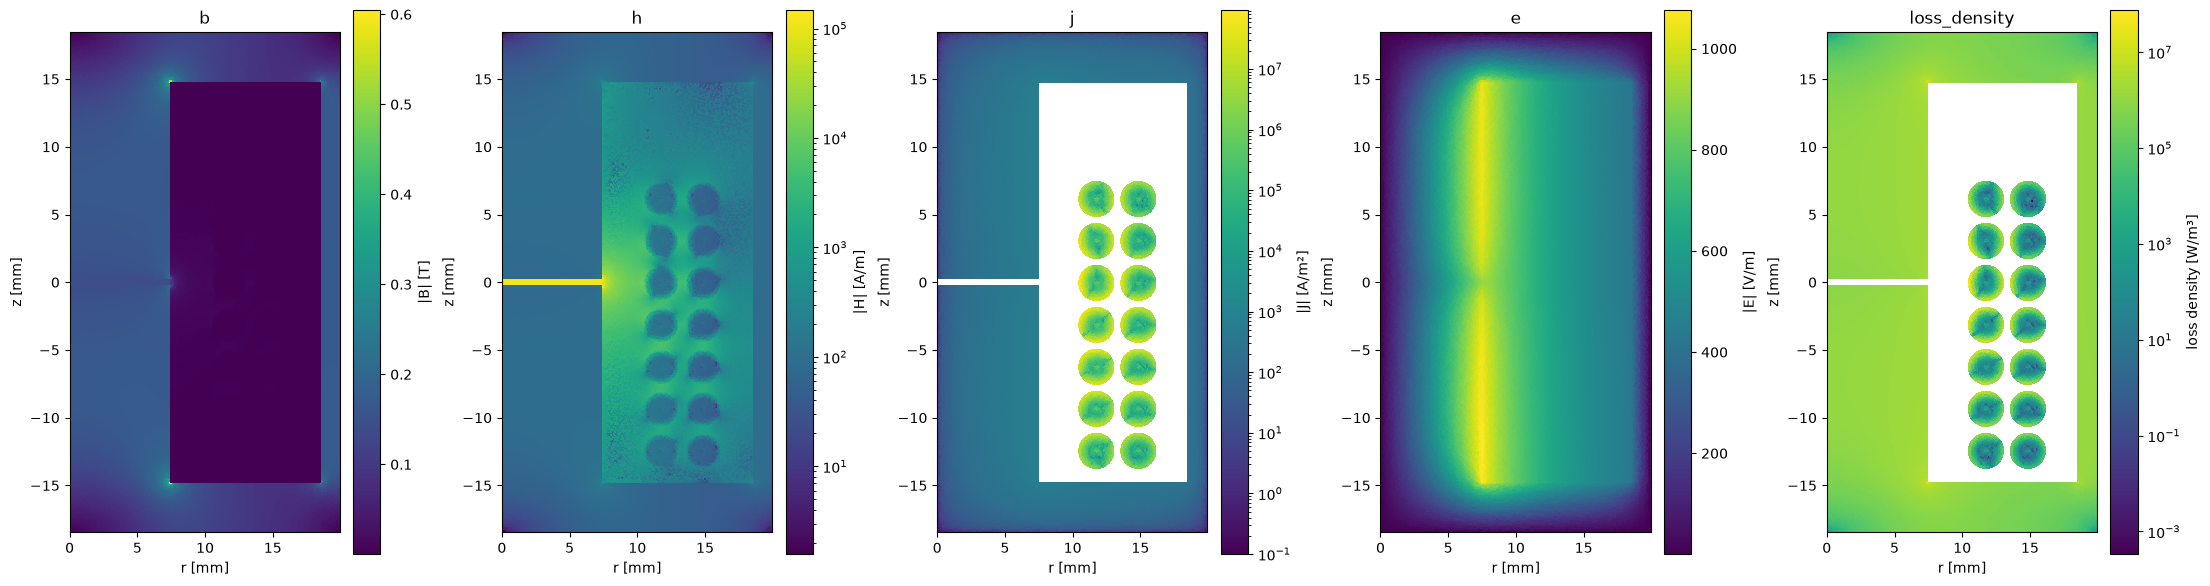

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(22, 6), constrained_layout=True)
plot_requests = [
    (PhysicalField.B, {}),
    (PhysicalField.H, {}),
    (PhysicalField.J, {}),
    (PhysicalField.E, {}),
    (PhysicalField.LOSS_DENSITY, {"litz_properties": litz_properties}),
]
for axis, (physical_field, kwargs) in zip(axes.flat, plot_requests):
    scale = "log" if physical_field in {PhysicalField.H, PhysicalField.J, PhysicalField.LOSS_DENSITY} else "linear"
    result.plot_physical_field(physical_field, ax=axis, color_scale=scale, **kwargs)
    axis.set_title(physical_field.value)
for axis in axes.flat[len(plot_requests):]:
    axis.set_visible(False)
plt.show()